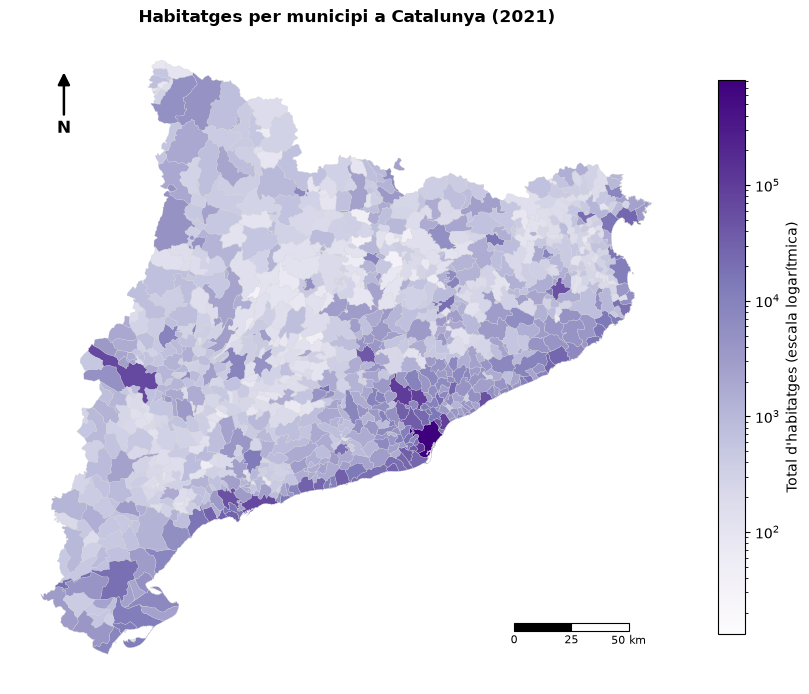

In [54]:
#Numero d'habitatges per municipi nomes per un any concret

import geopandas as gpd
import matplotlib.colors as colors
import matplotlib.patches as mpatches  
import matplotlib.pyplot as plt
import pandas as pd

municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra (p. ex., '080193')

arxius_config = {                                          
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     #    any: (nom_arxiu, files_a_saltar, nom_exacte_columna_total)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

any_obj = 2021   # Seleccionar l'any que es vol visualitzar (1981, 1991, 2001, 2011 o 2021)
nom_arxiu, skip, col_total = arxius_config[any_obj]    # Extreure el nom de l'arxiu, les files de capçalera i el nom de la columna per a aquell any
ruta_csv = rf"C:\Users\adria\Speculation-Map\DATA\Adria\{nom_arxiu}"

df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()        #Eliminar files sense codi municipal
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Netejar espais en blanc i assegurar que tots els codis tinguin 6 dígits
df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convertir la columna d'habitatges de l'any escollit a format numèric (els texts no vàlids passen a NaN)

gdf = municipis.merge(df_hab[["Codi", "Total"]], left_on="CODIMUNI", right_on="Codi", how="left", )
gdf = gdf.to_crs(epsg=25831)  # Canvia les coordenades a metres perquè el nord quedi amunt i l'escala en km sigui real

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

gdf.plot(
    column="Total",
    cmap="Purples",
    norm=colors.LogNorm(vmin=13, vmax=811106), # Escala logarítmica amb extrems fixos (1981-2021) per comparar anys
    edgecolor="lightgrey",
    linewidth=0.2,
    legend=True,
    legend_kwds={"label": "Total d'habitatges (escala logarítmica)", "shrink": 0.7},
    missing_kwds={"color": "#e0e0e0", "hatch": "///", "label": "Sense dades"},
    ax=ax,
)

#afegir fletxa nord
ax.annotate(
    "N",
    xy=(0.08, 0.94), #posicio punta
    xytext=(0.08, 0.85),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.8, mutation_scale=18),
)

#afegir barra d'escala
xmin, ymin, xmax, ymax = gdf.total_bounds  #obtenir distancies maximes del mapa de catalunya
longitud_total = 50_000  #distancia que equival la barra
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.012
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.8))
ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.8))

for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
    ax.text(x_inici + offset, y_inici - alcada_barra * 0.6, etiqueta, ha="center", va="top", fontsize=8)

ax.set_title(f"Habitatges per municipi a Catalunya ({any_obj})", fontweight="bold")
ax.set_axis_off()
plt.show()

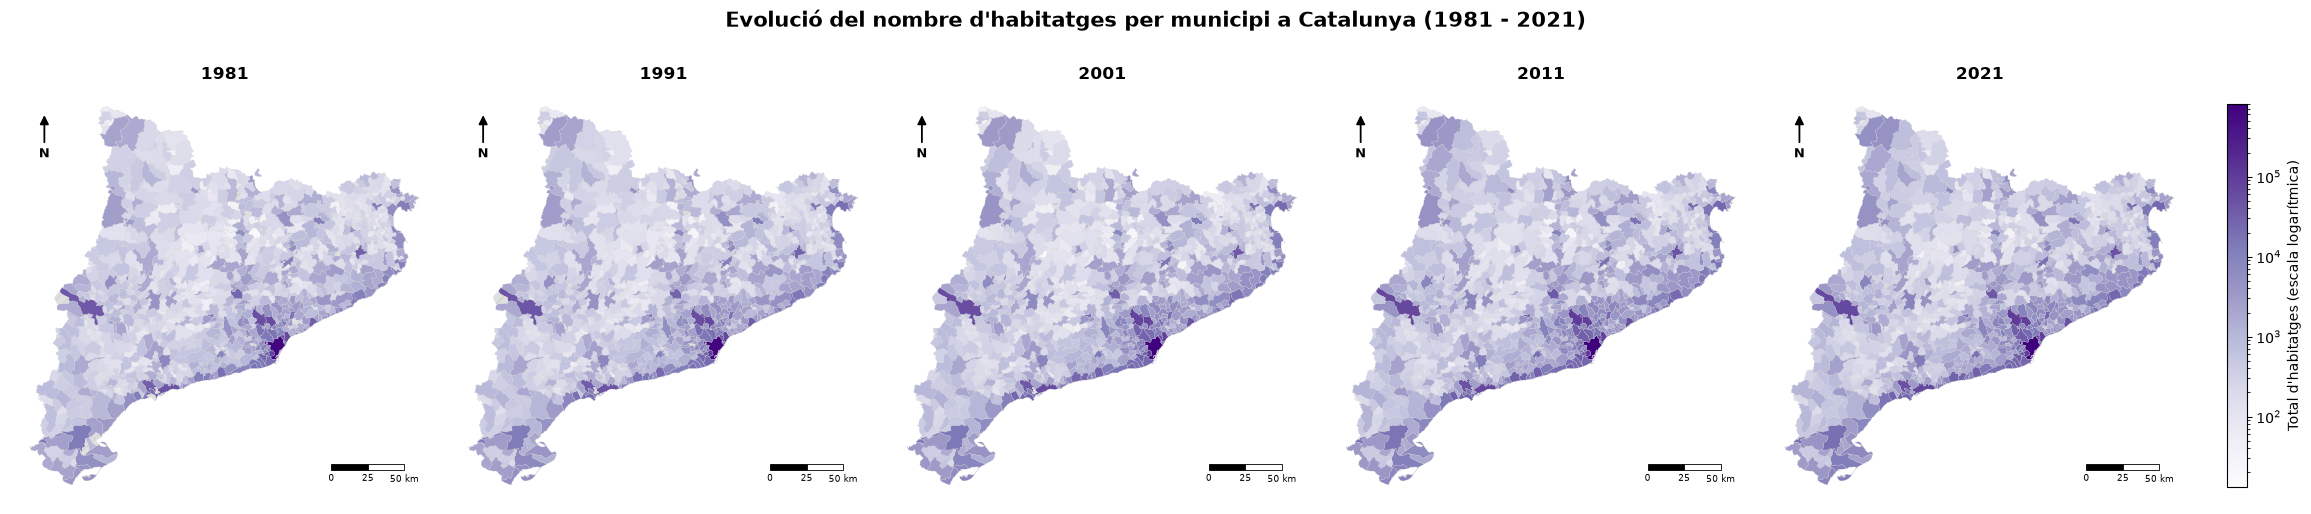

In [55]:
# Evolució del nombre d'habitatges per municipi (1981 - 2021) en 5 subplots seguits

import geopandas as gpd
import matplotlib.cm as cm  
import matplotlib.colors as colors
import matplotlib.patches as mpatches 
import matplotlib.pyplot as plt
import pandas as pd

municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra (p. ex., '080193')
municipis = municipis.to_crs(epsg=25831)  # Canvia les coordenades a metres perquè el nord quedi amunt i l'escala en km sigui real

arxius_config = {                                          
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     #    any: (nom_arxiu, files_a_saltar, nom_exacte_columna_total)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

norm = colors.LogNorm(vmin=13, vmax=811106) # Escala logarítmica amb extrems fixos (1981-2021) per comparar anys
cmap = "Purples"  # Paleta de colors 

fig, axes = plt.subplots(1, 5, figsize=(23, 5.5), layout="constrained")  

xmin, ymin, xmax, ymax = municipis.total_bounds  #obtenir distancies maximes del mapa de catalunya
longitud_total = 50_000  #distancia que equival la barra
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.015
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Recórrer cada subplot (ax) juntament amb el seu any i configuració 
for ax, (any_obj, (nom_arxiu, skip, col_total)) in zip(axes, arxius_config.items()):
    ruta_csv = rf"C:\Users\adria\Speculation-Map\DATA\Adria\{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        #Eliminar files sense codi municipal
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Netejar espais en blanc i assegurar que tots els codis tinguin 6 dígits
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convertir la columna d'habitatges de l'any escollit a format numèric (els texts no vàlids passen a NaN)

    gdf = municipis.merge(df_hab[["Codi", "Total"]], left_on="CODIMUNI", right_on="Codi", how="left", )

    gdf.plot(
        column="Total",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.15,
        legend=False,  # Desactivar llegenda individual per no repetir-la 5 vegades
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    #afegir fletxa nord
    ax.annotate(
        "N",
        xy=(0.08, 0.94), #posicio punta
        xytext=(0.08, 0.84),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.3, mutation_scale=13),
    )

    #afegir barra d'escala
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.6))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.6))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.7, etiqueta, ha="center", va="top", fontsize=6.5)

    ax.set_title(f"{any_obj}", fontweight="bold", fontsize=12)  # Posar l'any com a títol de cada subplot
    ax.set_axis_off()

# Única barra de color compartida a la dreta per a tots els subplots
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes, shrink=0.75, pad=0.015)
cbar.set_label("Total d'habitatges (escala logarítmica)", fontsize=10)


fig.suptitle("Evolució del nombre d'habitatges per municipi a Catalunya (1981 - 2021)", fontweight="bold", fontsize=15)  # Títol general de tota la figura
plt.show()

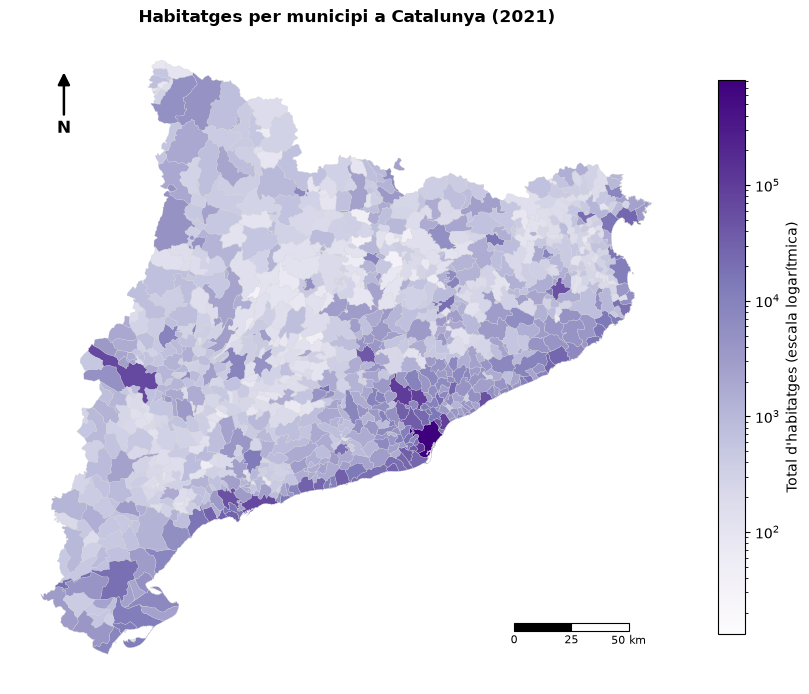

In [56]:
# Evolució temporal del nombre d'habitatges per municipi a Catalunya (1981 - 2021) en format GIF

import geopandas as gpd
import matplotlib.animation as animation  
import matplotlib.colors as colors
import matplotlib.patches as mpatches 
import matplotlib.pyplot as plt
import pandas as pd

municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra (p. ex., '080193')
municipis = municipis.to_crs(epsg=25831)  # Canvia les coordenades a metres perquè el nord quedi amunt i l'escala en km sigui real

arxius_config = {                                          
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     #    any: (nom_arxiu, files_a_saltar, nom_exacte_columna_total)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

anys = list(arxius_config.keys())  # Llista ordenada amb els 5 anys censals
dades_per_any = {}  # Diccionari per guardar els GeoDataFrames ja creuats de cada any

# Llegir i preparar les dades de tots els anys abans de generar l'animació
for any_obj, (nom_arxiu, skip, col_total) in arxius_config.items():
    ruta_csv = rf"C:\Users\adria\Speculation-Map\DATA\Adria\{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        #Eliminar files sense codi municipal
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Netejar espais en blanc i assegurar que tots els codis tinguin 6 dígits
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convertir la columna d'habitatges de l'any escollit a format numèric (els texts no vàlids passen a NaN)

    dades_per_any[any_obj] = municipis.merge(df_hab[["Codi", "Total"]], left_on="CODIMUNI", right_on="Codi", how="left", )

norm = colors.LogNorm(vmin=13, vmax=811106) # Escala logarítmica amb extrems fixos (1981-2021) per comparar anys
cmap = "Purples"  # Paleta de colors

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

# Dibuixar un primer mapa base per generar la barra de color una sola vegada
dades_per_any[anys[0]].plot(
    column="Total",
    cmap=cmap,
    norm=norm,
    legend=True,
    legend_kwds={"label": "Total d'habitatges (escala logarítmica)", "shrink": 0.7},
    ax=ax,
)

xmin, ymin, xmax, ymax = municipis.total_bounds  #obtenir distancies maximes del mapa de catalunya
longitud_total = 50_000  #distancia que equival la barra
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.012
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Funció que redibuixa el mapa per a cada any de l'animació
def actualitzar_fotograma(any_obj):
    ax.clear()  # Esborrar el mapa anterior sense eliminar la barra de color

    gdf = dades_per_any[any_obj]
    gdf.plot(
        column="Total",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.2,
        legend=False,  # La barra de color ja s'ha creat fora de la funció
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    #afegir fletxa nord
    ax.annotate(
        "N",
        xy=(0.08, 0.94), #posicio punta
        xytext=(0.08, 0.85),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.8, mutation_scale=18),
    )

    #afegir barra d'escala
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.8))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.8))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.6, etiqueta, ha="center", va="top", fontsize=8)

    ax.set_title(f"Habitatges per municipi a Catalunya ({any_obj})", fontweight="bold")
    ax.set_axis_off()

# Crear l'animació (interval=1500 ms -> 1.5 segons per any)
ani = animation.FuncAnimation(fig, actualitzar_fotograma, frames=anys, interval=1500, repeat=True)
ruta_gif = r"C:\Users\adria\Speculation-Map\evolucio_habitatges_1981_2021.gif"
ani.save(ruta_gif, writer=animation.PillowWriter(fps=1/1.5), dpi=200)

plt.show()

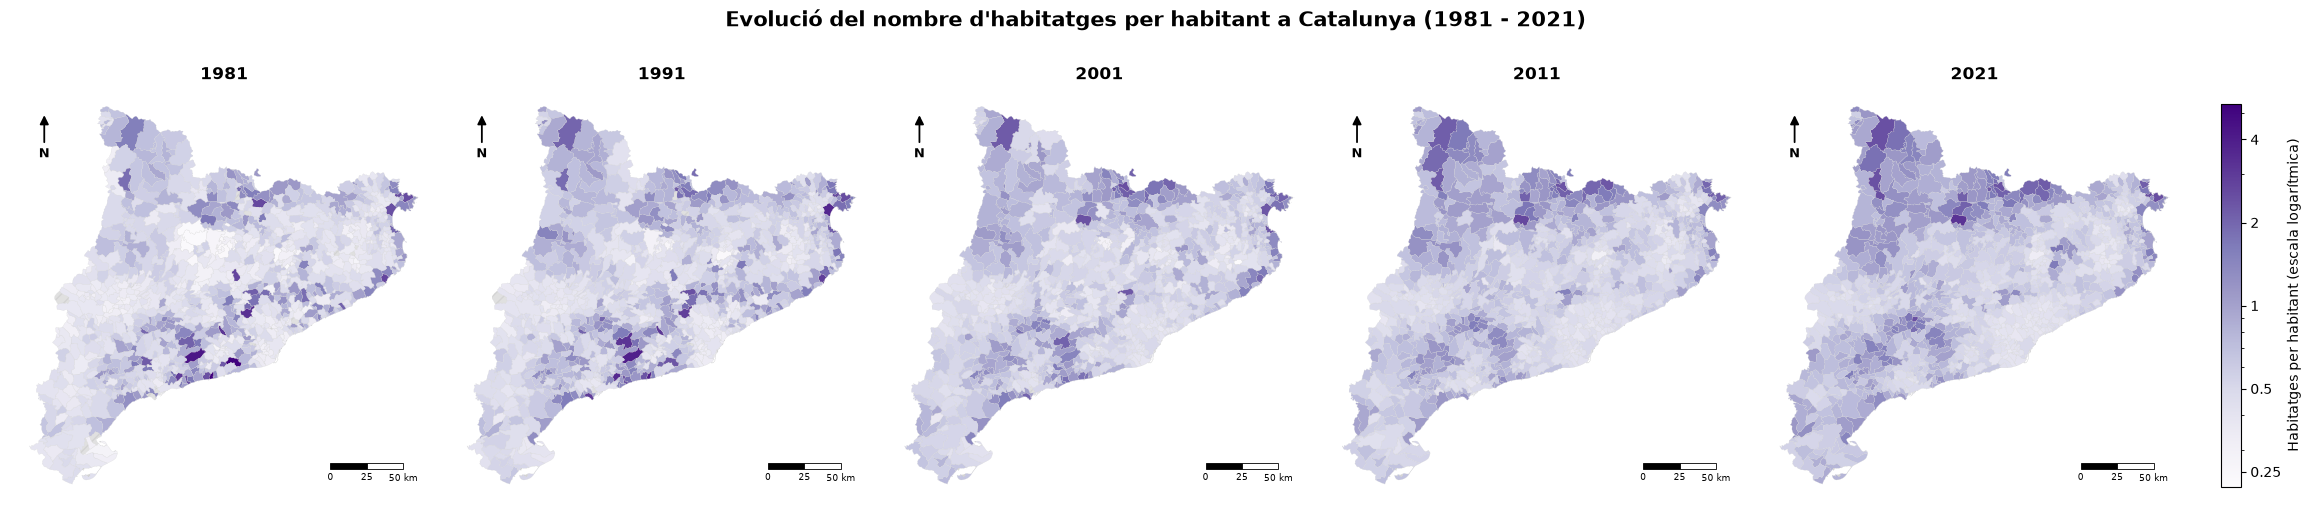

In [57]:
# Evolució de la ràtio d'habitatges per habitant per municipi a Catalunya (1981 - 2021)

import geopandas as gpd
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra (p. ex., '080193')
municipis = municipis.to_crs(epsg=25831)  # Canvia les coordenades a metres perquè el nord quedi amunt i l'escala en km sigui real

# Carregar i netejar les dades de població (full 'Dades' de poblacio_codis.xlsx)
ruta_pob = r"C:\Users\adria\Speculation-Map\DATA\Adria\poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})  # Llegir el full 'Dades' forçant la 1a columna com a text per conservar el zero inicial
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Reanomenar les dues primeres columnes
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Omplir cap avall el codi municipal i assegurar 6 dígits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Quedar-se només amb codis numèrics vàlids (elimina 'TOTAL' i les notes finals)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convertir l'any a enter
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")  # Convertir la població total a numèric

arxius_config = {
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     #    any: (nom_arxiu, files_a_saltar, nom_exacte_columna_total)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

norm = colors.LogNorm(vmin=0.22, vmax=5.4)  # Escala logarítmica amb extrems fixos (1981-2021) de la ràtio habitatges/habitant
cmap = "Purples"  # Paleta de colors

fig, axes = plt.subplots(1, 5, figsize=(23, 5.5), layout="constrained")

xmin, ymin, xmax, ymax = municipis.total_bounds  #obtenir distancies maximes del mapa de catalunya
longitud_total = 50_000  #distancia que equival la barra
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.015
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Recórrer cada subplot (ax) juntament amb el seu any i configuració
for ax, (any_obj, (nom_arxiu, skip, col_total)) in zip(axes, arxius_config.items()):
    ruta_csv = rf"C:\Users\adria\Speculation-Map\DATA\Adria\{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        #Eliminar files sense codi municipal
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Netejar espais en blanc i assegurar que tots els codis tinguin 6 dígits
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convertir la columna d'habitatges de l'any escollit a format numèric (els texts no vàlids passen a NaN)

    # Filtrar la població de l'any actual, creuar-la amb habitatges i calcular la ràtio
    df_pob_any = df_pob[df_pob["Any"] == any_obj][["Codi", "Poblacio"]]
    df_combinat = df_hab[["Codi", "Total"]].merge(df_pob_any, on="Codi", how="inner")
    df_combinat["Hab_per_hab"] = df_combinat["Total"] / df_combinat["Poblacio"]

    gdf = municipis.merge(df_combinat[["Codi", "Hab_per_hab"]], left_on="CODIMUNI", right_on="Codi", how="left")

    gdf.plot(
        column="Hab_per_hab",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.15,
        legend=False,  # Desactivar llegenda individual per no repetir-la 5 vegades
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    #afegir fletxa nord
    ax.annotate(
        "N",
        xy=(0.08, 0.94), #posicio punta
        xytext=(0.08, 0.84),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.3, mutation_scale=13),
    )

    #afegir barra d'escala
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.6))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.6))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.7, etiqueta, ha="center", va="top", fontsize=6.5)

    ax.set_title(f"{any_obj}", fontweight="bold", fontsize=12)  # Posar l'any com a títol de cada subplot
    ax.set_axis_off()

# Única barra de color compartida a la dreta per a tots els subplots
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes, shrink=0.75, pad=0.015)

# valors de la barra lateral
cbar.set_ticks([0.25, 0.5, 1, 2, 4])
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:g}"))
cbar.ax.yaxis.set_minor_formatter(ticker.NullFormatter())

cbar.set_label("Habitatges per habitant (escala logarítmica)", fontsize=10)

fig.suptitle("Evolució del nombre d'habitatges per habitant a Catalunya (1981 - 2021)", fontweight="bold", fontsize=15)  # Títol general de tota la figura
plt.show()

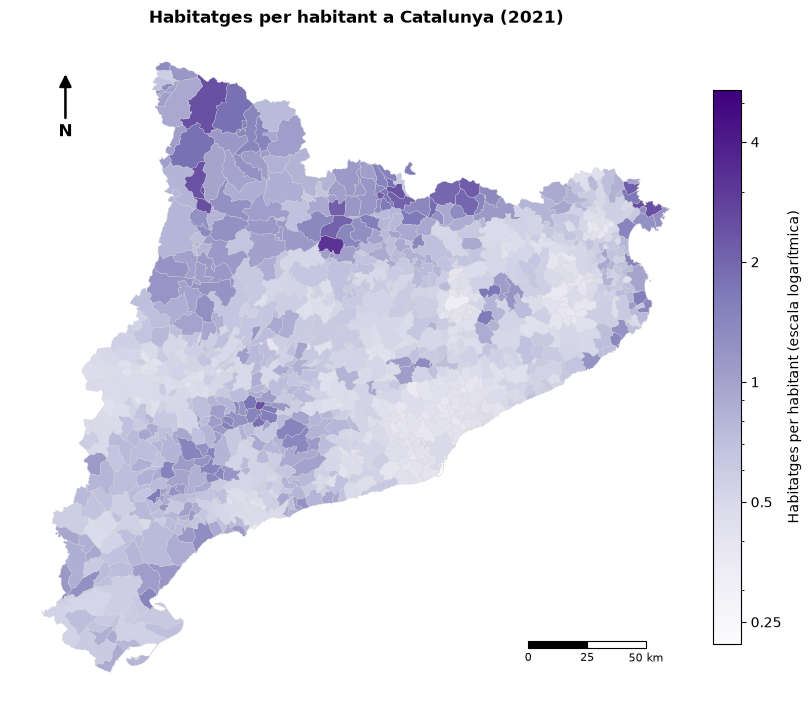

In [58]:
# Evolució temporal de la ràtio d'habitatges per habitant per municipi a Catalunya (1981 - 2021) en format GIF

import geopandas as gpd
import matplotlib.animation as animation
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra (p. ex., '080193')
municipis = municipis.to_crs(epsg=25831)  # Canvia les coordenades a metres perquè el nord quedi amunt i l'escala en km sigui real

# Carregar i netejar les dades de població (full 'Dades' de poblacio_codis.xlsx)
ruta_pob = r"C:\Users\adria\Speculation-Map\DATA\Adria\poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})  # Llegir el full 'Dades' forçant la 1a columna com a text per conservar el zero inicial
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Reanomenar les dues primeres columnes
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Omplir cap avall el codi municipal i assegurar 6 dígits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Quedar-se només amb codis numèrics vàlids (elimina 'TOTAL' i les notes finals)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convertir l'any a enter
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")  # Convertir la població total a numèric

arxius_config = {
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     #    any: (nom_arxiu, files_a_saltar, nom_exacte_columna_total)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

anys = list(arxius_config.keys())  # Llista ordenada amb els 5 anys censals
dades_per_any = {}  # Diccionari per guardar els GeoDataFrames ja creuats de cada any

# Llegir i preparar les dades de tots els anys abans de generar l'animació
for any_obj, (nom_arxiu, skip, col_total) in arxius_config.items():
    ruta_csv = rf"C:\Users\adria\Speculation-Map\DATA\Adria\{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        #Eliminar files sense codi municipal
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Netejar espais en blanc i assegurar que tots els codis tinguin 6 dígits
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convertir la columna d'habitatges de l'any escollit a format numèric (els texts no vàlids passen a NaN)

    # Filtrar la població de l'any actual, creuar-la amb habitatges i calcular la ràtio
    df_pob_any = df_pob[df_pob["Any"] == any_obj][["Codi", "Poblacio"]]
    df_combinat = df_hab[["Codi", "Total"]].merge(df_pob_any, on="Codi", how="inner")
    df_combinat["Hab_per_hab"] = df_combinat["Total"] / df_combinat["Poblacio"]

    dades_per_any[any_obj] = municipis.merge(df_combinat[["Codi", "Hab_per_hab"]], left_on="CODIMUNI", right_on="Codi", how="left")

norm = colors.LogNorm(vmin=0.22, vmax=5.4)  # Escala logarítmica amb extrems fixos (1981-2021) de la ràtio habitatges/habitant
cmap = "Purples"  # Paleta de colors

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

# Única barra de color creada una sola vegada fora de l'animació
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.015)

# valors de la barra lateral
cbar.set_ticks([0.25, 0.5, 1, 2, 4])
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:g}"))
cbar.ax.yaxis.set_minor_formatter(ticker.NullFormatter())
cbar.set_label("Habitatges per habitant (escala logarítmica)", fontsize=10)

xmin, ymin, xmax, ymax = municipis.total_bounds  #obtenir distancies maximes del mapa de catalunya
longitud_total = 50_000  #distancia que equival la barra
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.012
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Funció que redibuixa el mapa per a cada any de l'animació
def actualitzar_fotograma(any_obj):
    ax.clear()  # Esborrar el mapa anterior sense eliminar la barra de color

    gdf = dades_per_any[any_obj]
    gdf.plot(
        column="Hab_per_hab",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.2,
        legend=False,  # La barra de color ja s'ha creat fora de la funció
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    #afegir fletxa nord
    ax.annotate(
        "N",
        xy=(0.08, 0.94), #posicio punta
        xytext=(0.08, 0.85),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.8, mutation_scale=18),
    )

    #afegir barra d'escala
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.8))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.8))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.6, etiqueta, ha="center", va="top", fontsize=8)

    ax.set_title(f"Habitatges per habitant a Catalunya ({any_obj})", fontweight="bold")
    ax.set_axis_off()

# Crear l'animació (interval=1500 ms -> 1.5 segons per any)
ani = animation.FuncAnimation(fig, actualitzar_fotograma, frames=anys, interval=1500, repeat=True)
ruta_gif = r"C:\Users\adria\Speculation-Map\evolucio_habitatges_per_habitant_1981_2021.gif"
ani.save(ruta_gif, writer=animation.PillowWriter(fps=1/1.5), dpi=200)

plt.show()

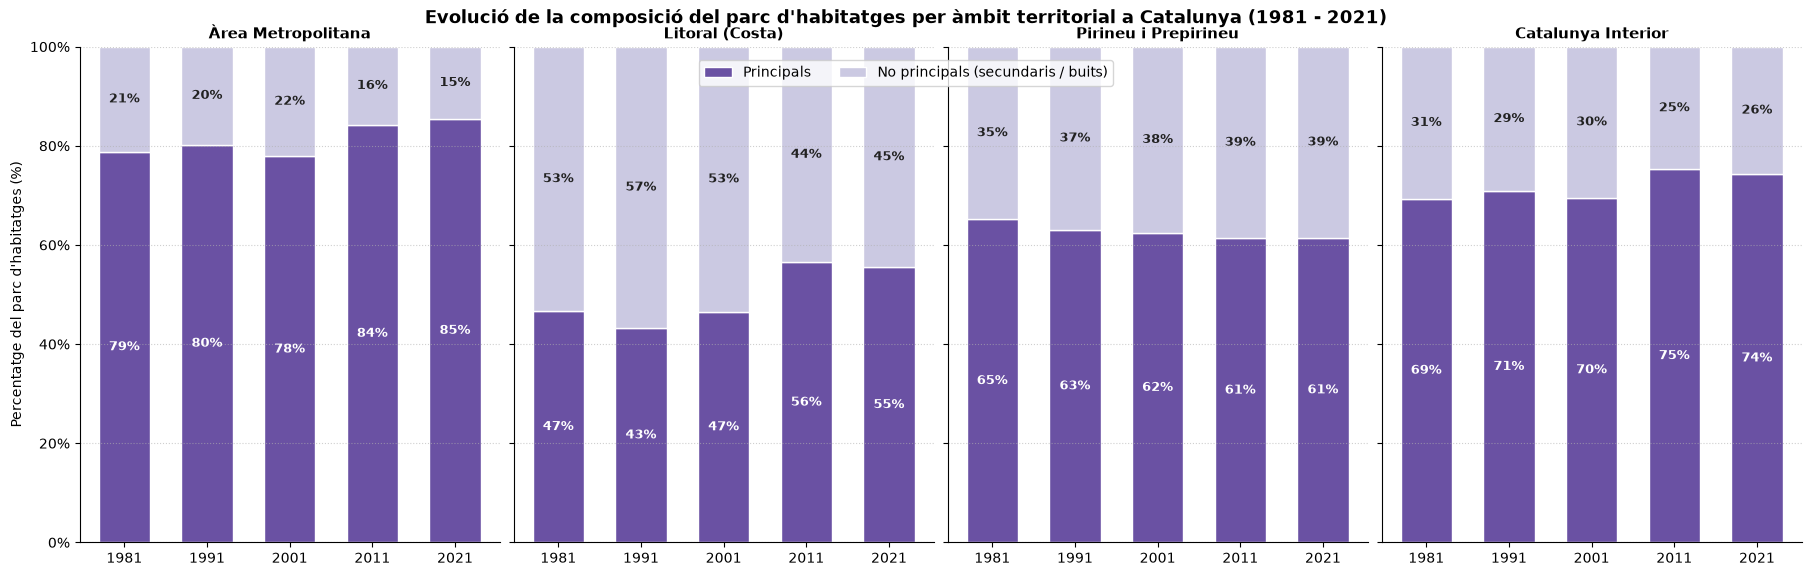

In [59]:
# Evolució de la composició del parc d'habitatges (% Principals vs. % No principals) per àmbit territorial (1981 - 2021)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# 1. Carregar capa geogràfica municipal per assignar cada municipi al seu àmbit territorial segons la comarca
municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json")
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)
municipis["CODICOMAR"] = municipis["CODICOMAR"].astype(str).str.zfill(2)

# Classificació dels codis comarcals de l'Idescat/ICGC en 4 grans àmbits territorials
comarques_amb = {"13", "11", "40", "41", "21", "17", "03"}  # Barcelonès, Baix Llobregat, Vallès Occ./Or., Maresme, Garraf, Alt Penedès
comarques_litoral = {"02", "10", "34", "36", "08", "12", "09", "22"}  # Costa Brava, Costa Daurada i Terres de l'Ebre litoral
comarques_pirineu = {"04", "05", "15", "25", "26", "31", "39", "07", "35"}  # Alt Pirineu, Aran, Ripollès, Berguedà i Solsonès

def assignar_ambit(codi_comarca):
    if codi_comarca in comarques_amb:
        return "Àrea Metropolitana"
    elif codi_comarca in comarques_litoral:
        return "Litoral (Costa)"
    elif codi_comarca in comarques_pirineu:
        return "Pirineu i Prepirineu"
    else:
        return "Catalunya Interior"

municipis["Ambit"] = municipis["CODICOMAR"].apply(assignar_ambit)
mapa_ambits = municipis[["CODIMUNI", "Ambit"]].drop_duplicates()

# 2. Configuració dels 5 arxius censals d'habitatges
arxius_config = {
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

# 3. Llegir els 5 anys, agrupar per àmbit territorial i calcular els percentatges
registres = []

for any_obj, (nom_arxiu, skip, col_total) in arxius_config.items():
    ruta_csv = rf"C:\Users\adria\Speculation-Map\DATA\Adria\{nom_arxiu}"
    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)

    # Detectar automàticament la columna d'habitatges principals (evitant 'no principals')
    cols_principals = [c for c in df_hab.columns if "princip" in c.lower() and "no " not in c.lower()]
    col_principal = cols_principals[0]

    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")
    df_hab["Principals"] = pd.to_numeric(df_hab[col_principal], errors="coerce")
    df_hab["No_principals"] = df_hab["Total"] - df_hab["Principals"]

    # Creuar amb l'àmbit territorial i sumar el total d'habitatges de cada zona
    df_zona = df_hab.merge(mapa_ambits, left_on="Codi", right_on="CODIMUNI", how="inner")
    resum = df_zona.groupby("Ambit", as_index=False)[["Total", "Principals", "No_principals"]].sum()
    resum["Any"] = str(any_obj)
    resum["Pct_principals"] = (resum["Principals"] / resum["Total"]) * 100
    resum["Pct_no_principals"] = (resum["No_principals"] / resum["Total"]) * 100
    registres.append(resum)

df_final = pd.concat(registres, ignore_index=True)

# 4. Dibuixar el gràfic de barres apilades al 100% (1 fila x 4 àmbits territorials)
ambits_ordre = ["Àrea Metropolitana", "Litoral (Costa)", "Pirineu i Prepirineu", "Catalunya Interior"]
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5), sharey=True, layout="constrained")

color_principal = "#6a51a3"      # Morat fosc per a habitatges principals
color_no_principal = "#cbc9e2"   # Lila clar per a habitatges no principals (secundaris + buits)

for ax, ambit in zip(axes, ambits_ordre):
    sub = df_final[df_final["Ambit"] == ambit].sort_values("Any")

    # Barra inferior: % Principals
    barres_p = ax.bar(sub["Any"], sub["Pct_principals"], color=color_principal, edgecolor="white", width=0.62, label="Principals")
    # Barra superior: % No principals (apilada sobre Principals)
    barres_np = ax.bar(
        sub["Any"],
        sub["Pct_no_principals"],
        bottom=sub["Pct_principals"],
        color=color_no_principal,
        edgecolor="white",
        width=0.62,
        label="No principals (secundaris / buits)",
    )

    # Escriure el percentatge exacte dins de cada segment de la barra
    for b_p, b_np in zip(barres_p, barres_np):
        alt_p = b_p.get_height()
        alt_np = b_np.get_height()
        x_centre = b_p.get_x() + b_p.get_width() / 2

        if alt_p >= 8:
            ax.text(x_centre, alt_p / 2, f"{alt_p:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
        if alt_np >= 8:
            ax.text(x_centre, alt_p + alt_np / 2, f"{alt_np:.0f}%", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9)

    ax.set_title(ambit, fontweight="bold", fontsize=11)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(ticker.PercentFormatter())
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Percentatge del parc d'habitatges (%)", fontsize=10)

# Llegenda única compartida a la part superior
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=2, frameon=True, fontsize=10)

fig.suptitle("Evolució de la composició del parc d'habitatges per àmbit territorial a Catalunya (1981 - 2021)", fontweight="bold", fontsize=13, y=1.02)
plt.show()

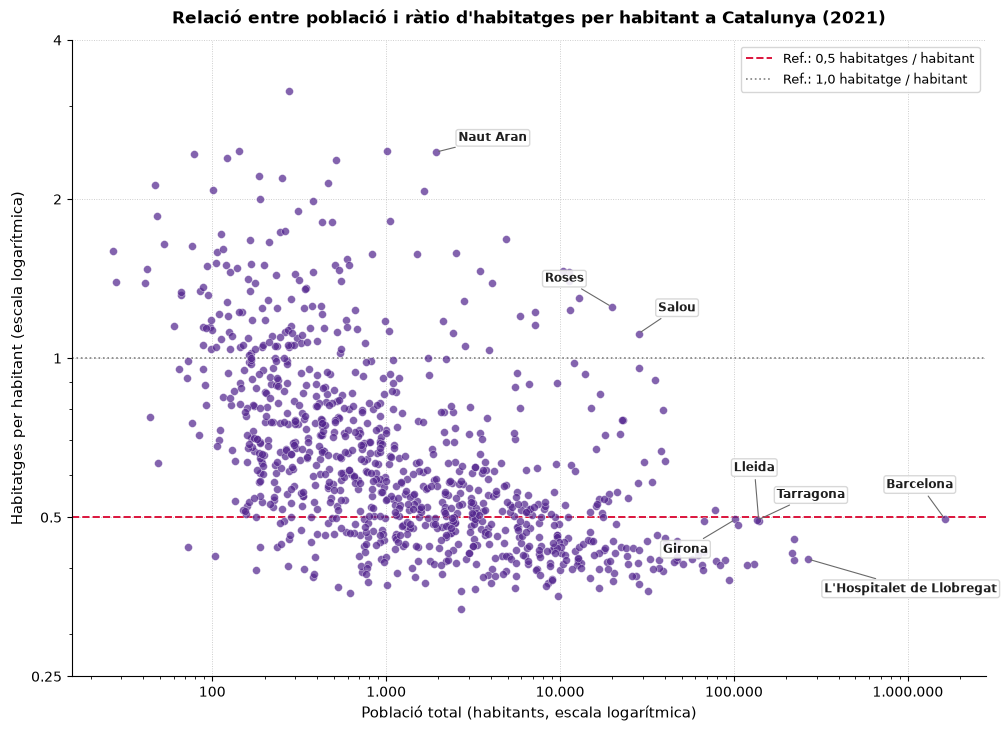

In [61]:
# Relació entre població i ràtio d'habitatges per habitant a Catalunya (2021)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra (p. ex., '080193')

# Carregar i netejar les dades de població 
ruta_pob = r"C:\Users\adria\Speculation-Map\DATA\Adria\poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str}) 
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Reanomenar les dues primeres columnes
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Omplir cap avall el codi municipal i assegurar 6 dígits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Quedar-se només amb codis numèrics vàlids (elimina 'TOTAL' i les notes finals)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convertir l'any a enter
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")  # Convertir la població total a numèric

# Llegir i preparar les dades d'habitatges del 2021
ruta_hab = r"C:\Users\adria\Speculation-Map\DATA\Adria\habitatges2021.csv"
df_hab = pd.read_csv(ruta_hab, sep=";", skiprows=5, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()        #Eliminar files sense codi municipal
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Netejar espais en blanc i assegurar que tots els codis tinguin 6 dígits
df_hab["Total"] = pd.to_numeric(df_hab["Total habitatges familiars"], errors="coerce")   # Convertir la columna d'habitatges de l'any escollit a format numèric (els texts no vàlids passen a NaN)

# Filtrar la població del 2021, creuar-la amb habitatges i nom del municipi, i calcular la ràtio
pob_2021 = df_pob[df_pob["Any"] == 2021][["Codi", "Poblacio"]]
df = (
    df_hab[["Codi", "Total"]]
    .merge(pob_2021, on="Codi", how="inner")
    .merge(municipis[["CODIMUNI", "NOMMUNI"]], left_on="Codi", right_on="CODIMUNI", how="inner")
    .dropna()
)
df = df[(df["Poblacio"] > 0) & (df["Total"] > 0)].copy()  # Eliminar valors no positius per poder aplicar escales logarítmiques
df["Hab_per_hab"] = df["Total"] / df["Poblacio"]

fig, ax = plt.subplots(figsize=(10, 7.2), layout="constrained")

# Dibuixar gràfic de dispersió (Població vs. Ràtio)
ax.scatter(
    df["Poblacio"],
    df["Hab_per_hab"],
    color="#54278f",
    s=32,
    alpha=0.72,
    edgecolors="white",
    linewidth=0.3,
    zorder=3,
)

# Línies horitzontals de referència
ax.axhline(0.5, color="crimson", linestyle="--", linewidth=1.4, zorder=2, label="Ref.: 0,5 habitatges / habitant")
ax.axhline(1.0, color="grey", linestyle=":", linewidth=1.2, zorder=2, label="Ref.: 1,0 habitatge / habitant")

# Llista de municipis a etiquetar: (patró_cerca, etiqueta_a_mostrar, desplaçament_x, desplaçament_y)
etiquetes_destacades = [
    (r"^Barcelona$", "Barcelona", -42, 22),
    (r"Hospitalet de Llobregat", "L'Hospitalet de Llobregat", 12, -24),
    (r"^Lleida$", "Lleida", -18, 36),
    (r"^Tarragona$", "Tarragona", 14, 16),
    (r"^Girona$", "Girona", -52, -24),
    (r"^Salou$", "Salou", 14, 16),
    (r"^Roses$", "Roses", -48, 18),
    (r"^Naut Aran$", "Naut Aran", 16, 8),
]

# Recórrer la llista i afegir l'etiqueta a cada municipi destacat
for patro, etiqueta, dx, dy in etiquetes_destacades:
    fila = df[df["NOMMUNI"].str.contains(patro, case=False, regex=True)]
    if not fila.empty:
        r = fila.iloc[0]
        ax.annotate(
            etiqueta,
            xy=(r["Poblacio"], r["Hab_per_hab"]),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            color="#1f1f1f",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="lightgrey", alpha=0.88),
            arrowprops=dict(arrowstyle="-", color="dimgray", lw=0.8),
            zorder=4,
        )

# Configurar escales logarítmiques als dos eixos
ax.set_xscale("log")
ax.set_yscale("log")

# Formatejar els números dels eixos sense notació científica
fmt_enter = ticker.FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", "."))
fmt_decimal = ticker.FuncFormatter(lambda x, _: f"{x:g}")

ax.xaxis.set_major_formatter(fmt_enter)
ax.set_yticks([0.25, 0.5, 1, 2, 4])
ax.yaxis.set_major_formatter(fmt_decimal)
ax.yaxis.set_minor_formatter(ticker.NullFormatter())

ax.grid(True, which="major", linestyle=":", linewidth=0.65, alpha=0.7, zorder=1)  # Afegir quadrícula suau de fons
ax.spines["top"].set_visible(False)  # Amagar la vora superior del marc
ax.spines["right"].set_visible(False)  # Amagar la vora dreta del marc
ax.legend(loc="upper right", frameon=True, fontsize=9.5)  # Afegir llegenda de les línies de referència

ax.set_xlabel("Població total (habitants, escala logarítmica)", fontsize=10.5)
ax.set_ylabel("Habitatges per habitant (escala logarítmica)", fontsize=10.5)
ax.set_title(
    "Relació entre població i ràtio d'habitatges per habitant a Catalunya (2021)",
    fontweight="bold",
    fontsize=12.5,
    pad=12,
)

plt.show()

Text(0.5, 0.98, 'Anàlisi bivariant per municipi a Catalunya: comparativa per parelles (2021)')

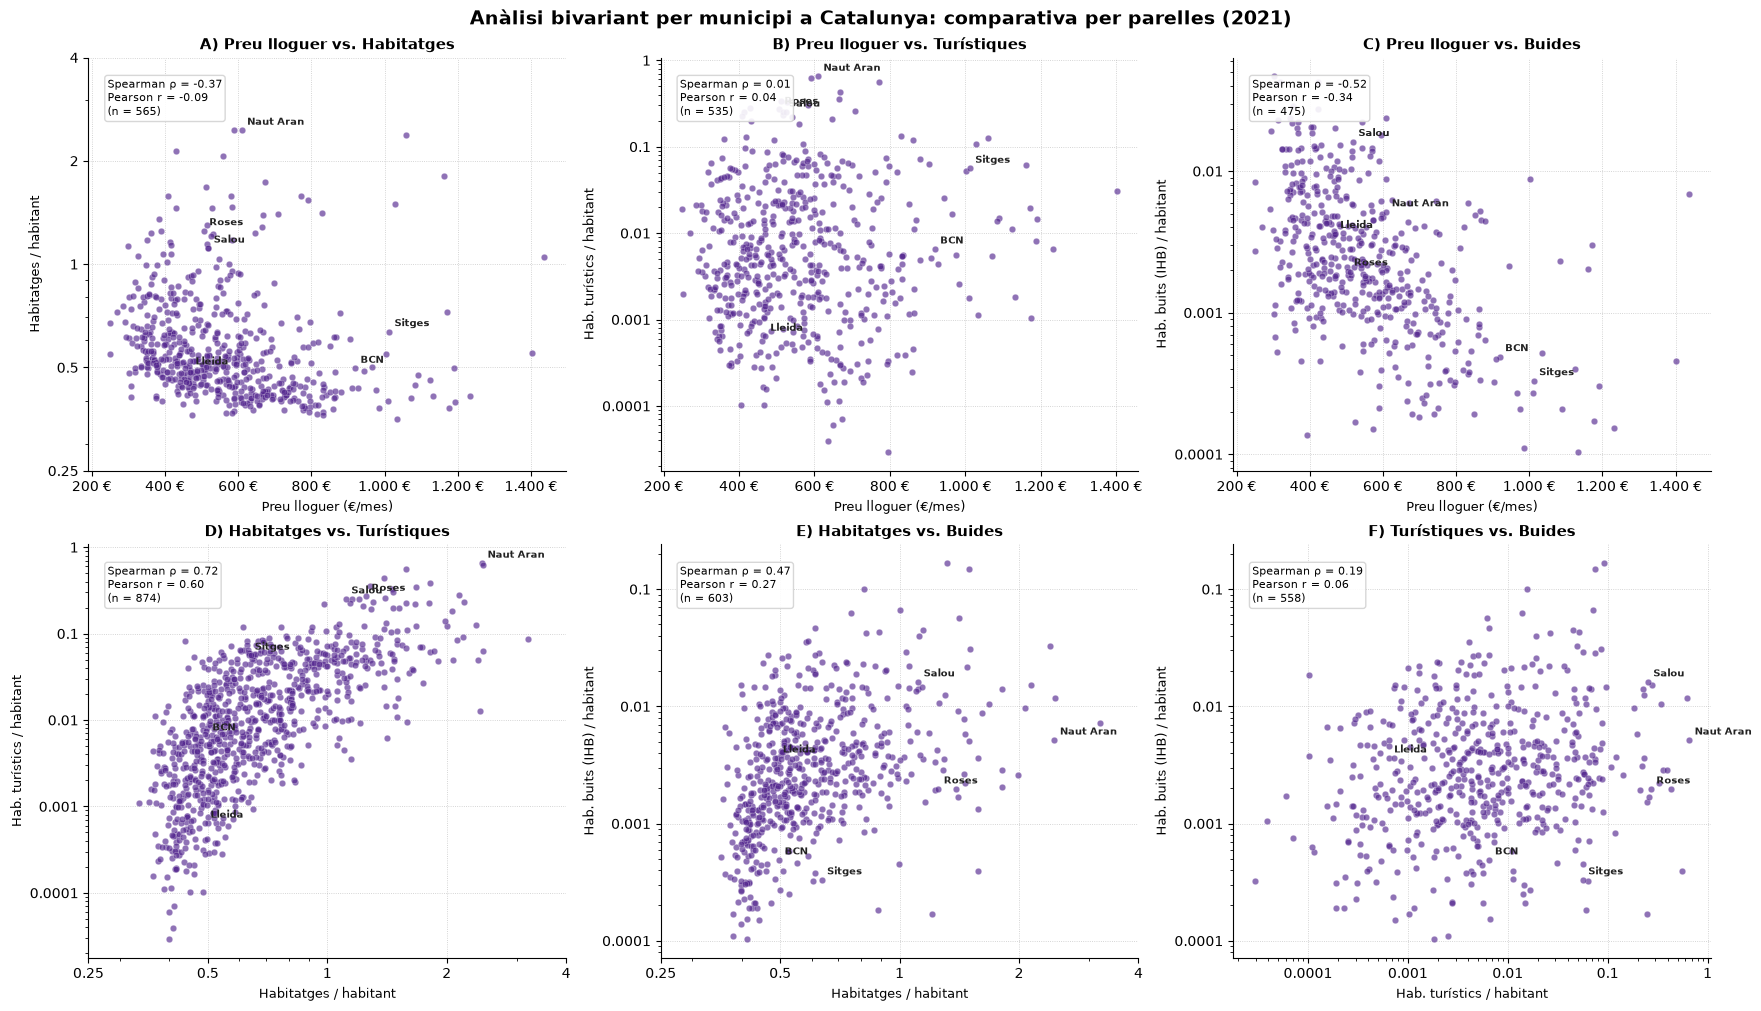

In [69]:
# Exploració per parelles (6 subplots): sense valors 0 i amb escales logarítmiques pures (2021)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# ==============================================================================
# 1. CAPA GEOGRÀFICA, POBLACIÓ I HABITATGES TOTALS (2021)
# ==============================================================================
municipis = gpd.read_file(r"C:\Users\adria\Speculation-Map\divisions-administratives-v2r1-municipis-1000000-20250730.json") #carregar capa geografica per municipis de catalunya
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convertir el codi municipal a text de 6 dígits amb zeros a l'esquerra

ruta_pob = r"C:\Users\adria\Speculation-Map\DATA\Adria\poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()
df_pob["Any"] = df_pob["Any"].astype(int)
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")
pob_2021 = df_pob[df_pob["Any"] == 2021][["Codi", "Poblacio"]]

ruta_hab = r"C:\Users\adria\Speculation-Map\DATA\Adria\habitatges2021.csv"
df_hab = pd.read_csv(ruta_hab, sep=";", skiprows=5, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)
df_hab["Total"] = pd.to_numeric(df_hab["Total habitatges familiars"], errors="coerce")

# ==============================================================================
# 2. DADES DE LLOGUER, HABITATGES TURÍSTICS I HABITATGES BUITS (2021)
# ==============================================================================
carpeta_otros = r"C:\Users\adria\Desktop\Master\Asignaturas\Analisi_i_visualització_de_dades_massives\Mio\Data\otros"

# 2A. Preu mitjà del lloguer (Mean_price.csv -> 2021 anual)
ruta_lloguer = r"C:\Users\adria\Speculation-Map\DATA\Pol\Mean_price.csv"
df_lloguer = pd.read_csv(ruta_lloguer, sep=";", dtype=str)
df_lloguer = df_lloguer[
    (df_lloguer["Àmbit territorial"] == "Municipi")
    & (df_lloguer["Any"] == "2021")
    & (df_lloguer["Període"] == "gener-desembre")
].copy()
df_lloguer["Codi5"] = df_lloguer["Codi territorial"].str.strip().str.zfill(5)
df_lloguer["Lloguer"] = pd.to_numeric(
    df_lloguer["Renda"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce",
)

# 2B. Habitatges d'ús turístic (Registre de Turisme de Catalunya)
ruta_tur = rf"{carpeta_otros}\Establiments_d’allotjament_turístic_inscrits_al_Registre_de_Turisme_de_Catalunya_20261119.csv"
df_tur = pd.read_csv(ruta_tur, dtype=str)
df_hut = df_tur[df_tur["Tipus establiment"] == "Habitatges d'ús turístic"].copy()
df_hut["Codi"] = df_hut["Codi Municipi (IDESCAT)"].str.strip().str.zfill(6)
tur_per_muni = df_hut.groupby("Codi").size().reset_index(name="Num_turistics")

# 2C. Habitatges buits (Impost sobre els habitatges buits - IHB, exercici 2021)
ruta_buits = rf"{carpeta_otros}\Impost_sobre_els_habitatges_buits_(IHB)_per_municipi_i_exercici_de_meritació_20261119.csv"
df_ihb = pd.read_csv(ruta_buits, dtype=str)
df_ihb_2021 = df_ihb[df_ihb["Any"] == "2021"].copy()
df_ihb_2021["Codi"] = df_ihb_2021["Codi"].str.strip().str.zfill(6)
df_ihb_2021["Habitatges"] = pd.to_numeric(df_ihb_2021["Habitatges"].str.replace(".", "", regex=False), errors="coerce")
buits_per_muni = df_ihb_2021.groupby("Codi")["Habitatges"].sum().reset_index(name="Num_buits")

# ==============================================================================
# 3. CREUAR TOTES LES VARIABLES I NORMALITZAR PER HABITANT (SENSE OMPLIR AMB 0)
# ==============================================================================
df_base = (
    df_hab[["Codi", "Total"]]
    .merge(pob_2021, on="Codi", how="inner")
    .merge(municipis[["CODIMUNI", "NOMMUNI"]], left_on="Codi", right_on="CODIMUNI", how="inner")
    .merge(tur_per_muni, on="Codi", how="left")
    .merge(buits_per_muni, on="Codi", how="left")
)
df_base = df_base.dropna(subset=["Total", "Poblacio"]).copy()
df_base = df_base[(df_base["Poblacio"] > 0) & (df_base["Total"] > 0)].copy()

# Calcular ràtios per habitant (els municipis sense registre queden com a NaN)
df_base["Hab_per_hab"] = df_base["Total"] / df_base["Poblacio"]
df_base["Tur_per_hab"] = df_base["Num_turistics"] / df_base["Poblacio"]
df_base["Buits_per_hab"] = df_base["Num_buits"] / df_base["Poblacio"]

# Afegir el preu del lloguer
df_base["Codi5"] = df_base["Codi"].str[:5]
df = df_base.merge(df_lloguer[["Codi5", "Lloguer"]], on="Codi5", how="left")

# ==============================================================================
# 4. GENERAR ELS 6 SUBPLOTS EN UNA GRAELLA 2x3 (NOMÉS VALORS > 0)
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(17.5, 10), layout="constrained")
axes = axes.flatten()

# Configuració de cada parella: (col_x, col_y, etiqueta_x, etiqueta_y, títol, escala_x, escala_y)
parelles = [
    ("Lloguer", "Hab_per_hab", "Preu lloguer (€/mes)", "Habitatges / habitant", "A) Preu lloguer vs. Habitatges", "linear", "log"),
    ("Lloguer", "Tur_per_hab", "Preu lloguer (€/mes)", "Hab. turístics / habitant", "B) Preu lloguer vs. Turístiques", "linear", "log"),
    ("Lloguer", "Buits_per_hab", "Preu lloguer (€/mes)", "Hab. buits (IHB) / habitant", "C) Preu lloguer vs. Buides", "linear", "log"),
    ("Hab_per_hab", "Tur_per_hab", "Habitatges / habitant", "Hab. turístics / habitant", "D) Habitatges vs. Turístiques", "log", "log"),
    ("Hab_per_hab", "Buits_per_hab", "Habitatges / habitant", "Hab. buits (IHB) / habitant", "E) Habitatges vs. Buides", "log", "log"),
    ("Tur_per_hab", "Buits_per_hab", "Hab. turístics / habitant", "Hab. buits (IHB) / habitant", "F) Turístiques vs. Buides", "log", "log"),
]

# Municipis clau per situar-se ràpidament a cada gràfic
municipis_ref = [
    (r"^Barcelona$", "BCN"),
    (r"^Salou$", "Salou"),
    (r"^Roses$", "Roses"),
    (r"^Naut Aran$", "Naut Aran"),
    (r"^Lleida$", "Lleida"),
    (r"^Sitges$", "Sitges"),
]

fmt_euros = ticker.FuncFormatter(lambda x, _: f"{int(x):,} €".replace(",", "."))
fmt_decimal = ticker.FuncFormatter(lambda x, _: f"{x:g}")

for ax, (col_x, col_y, lbl_x, lbl_y, titol, esc_x, esc_y) in zip(axes, parelles):
    # Eliminar files sense dada (NaN) o amb valor 0 en qualsevol dels dos eixos
    sub = df.dropna(subset=[col_x, col_y]).copy()
    sub = sub[(sub[col_x] > 0) & (sub[col_y] > 0)].copy()

    ax.scatter(
        sub[col_x],
        sub[col_y],
        color="#54278f",
        s=22,
        alpha=0.65,
        edgecolors="white",
        linewidth=0.25,
        zorder=3,
    )

    # Configurar escales de l'eix X
    if esc_x == "log":
        ax.set_xscale("log")
        if col_x == "Hab_per_hab":
            ax.set_xticks([0.25, 0.5, 1, 2, 4])
        ax.xaxis.set_major_formatter(fmt_decimal)
        ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.xaxis.set_major_formatter(fmt_euros)

    # Configurar escales de l'eix Y
    if esc_y == "log":
        ax.set_yscale("log")
        if col_y == "Hab_per_hab":
            ax.set_yticks([0.25, 0.5, 1, 2, 4])
        ax.yaxis.set_major_formatter(fmt_decimal)
        ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.yaxis.set_major_formatter(fmt_euros)

    # Calcular correlacions de Spearman (relació monòtona) i Pearson (lineal)
    rho = sub[col_x].corr(sub[col_y], method="spearman")
    r_pear = sub[col_x].corr(sub[col_y], method="pearson")
    ax.text(
        0.04,
        0.95,
        f"Spearman ρ = {rho:.2f}\nPearson r = {r_pear:.2f}\n(n = {len(sub)})",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="lightgrey", alpha=0.9),
        zorder=5,
    )

    # Etiquetar els municipis de referència
    for patro, nom_curt in municipis_ref:
        fila = sub[sub["NOMMUNI"].str.contains(patro, case=False, regex=True)]
        if not fila.empty:
            r = fila.iloc[0]
            ax.annotate(
                nom_curt,
                xy=(r[col_x], r[col_y]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=7.2,
                fontweight="bold",
                color="#222222",
                zorder=4,
            )

    ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.7, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel(lbl_x, fontsize=9.5)
    ax.set_ylabel(lbl_y, fontsize=9.5)
    ax.set_title(titol, fontweight="bold", fontsize=10.5)

fig.suptitle(
    "Anàlisi bivariant per municipi a Catalunya: comparativa per parelles (2021)",
    fontweight="bold",
    fontsize=13.5,
)